In [11]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Conv2D, MaxPooling2D
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(1)


In [12]:
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()


x_train_2d = x_train_raw.astype('float32')
x_test_2d = x_test_raw.astype('float32')
gray_scale = 255
x_train_2d /= gray_scale
x_test_2d /= gray_scale


x_train_mlp = x_train_2d
x_test_mlp = x_test_2d

x_train_cnn = np.reshape(x_train_2d, (60000, 28, 28, 1))
x_test_cnn = np.reshape(x_test_2d, (10000, 28, 28, 1))

num_classes = 10
y_train_categorical = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_categorical = tf.keras.utils.to_categorical(y_test, num_classes)

assert np.array_equal(x_test_mlp, np.squeeze(x_test_cnn, axis=-1))
assert np.array_equal(np.argmax(y_test_categorical, axis=1), y_test)

print("테스트 이미지 수:", len(y_test))
print("MLP 테스트 입력 모양:", x_test_mlp.shape)
print("CNN 테스트 입력 모양:", x_test_cnn.shape)


테스트 이미지 수: 10000
MLP 테스트 입력 모양: (10000, 28, 28)
CNN 테스트 입력 모양: (10000, 28, 28, 1)


In [13]:
mlp_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='sigmoid'),
    Dense(128, activation='sigmoid'),
    Dense(10, activation='softmax'),
])

mlp_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mlp_model.summary()

mlp_history = mlp_model.fit(
    x_train_mlp,
    y_train,
    epochs=10,
    batch_size=500,
    validation_split=0.1
)

mlp_loss, mlp_accuracy = mlp_model.evaluate(
    x_test_mlp, y_test, verbose=2
)
print(f"MLP test loss: {mlp_loss:.4f}")
print(f"MLP test accuracy: {mlp_accuracy * 100:.2f}%")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7011 - loss: 1.2124 - val_accuracy: 0.9000 - val_loss: 0.4703
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8953 - loss: 0.4062 - val_accuracy: 0.9278 - val_loss: 0.2763
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9170 - loss: 0.2963 - val_accuracy: 0.9378 - val_loss: 0.2225
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9279 - loss: 0.2496 - val_accuracy: 0.9462 - val_loss: 0.1924
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9369 - loss: 0.2179 - val_accuracy: 0.9530 - val_loss: 0.1710
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9438 - loss: 0.1930 - val_accuracy: 0.9580 - val_loss: 0.1546
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9498 - loss: 0.1724 - val_accuracy: 0.9610 - val_loss: 0.1415
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9549 - loss: 0.1548 - val_accu

In [14]:
cnn_model = Sequential()
cnn_model.add(Conv2D(16, kernel_size=(5, 5), activation='relu',
                     input_shape=(28, 28, 1), padding='same'))
cnn_model.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model.add(Conv2D(32, kernel_size=(5, 5), activation='relu',
                     padding='same'))
cnn_model.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model.add(Flatten())
cnn_model.add(Dense(128, activation='relu'))
cnn_model.add(Dense(num_classes, activation='softmax'))

cnn_model.compile(
    loss=categorical_crossentropy,
    optimizer=Adam(),
    metrics=['accuracy']
)

cnn_model.summary()

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train_categorical,
    batch_size=500,
    epochs=10,
    verbose=1,
    validation_split=0.1
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test_cnn, y_test_categorical, verbose=0
)
print(f"CNN test loss: {cnn_loss:.4f}")
print(f"CNN test accuracy: {cnn_accuracy * 100:.2f}%")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │       200,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 215,370 (841.29 KB)

 Trainable params: 215,370 (841.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 476ms/step - accuracy: 0.8662 - loss: 0.4713 - val_accuracy: 0.9665 - val_loss: 0.1187
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 83s 487ms/step - accuracy: 0.9662 - loss: 0.1101 - val_accuracy: 0.9808 - val_loss: 0.0730
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 486ms/step - accuracy: 0.9769 - loss: 0.0734 - val_accuracy: 0.9838 - val_loss: 0.0589
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 83s 498ms/step - accuracy: 0.9827 - loss: 0.0562 - val_accuracy: 0.9853 - val_loss: 0.0517
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 489ms/step - accuracy: 0.9861 - loss: 0.0461 - val_accuracy: 0.9868 - val_loss: 0.0469
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 493ms/step - accuracy: 0.9881 - loss: 0.0388 - val_accuracy: 0.9870 - val_loss: 0.0467
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 82s 493ms/step - accuracy: 0.9903 - loss: 0.0334 - val_accuracy: 0.9862 - val_loss: 0.0466
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 488ms/step - accuracy: 0.9919 - loss: 0

,Model,Test loss,Test accuracy (%)
0,MLP,0.1335,96.04
1,CNN,0.0388,98.79


CNN 정확도가 MLP보다 2.75%p 높습니다.


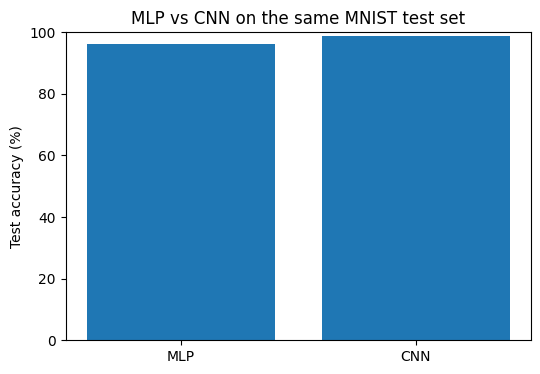

In [15]:
comparison = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Test loss": [mlp_loss, cnn_loss],
    "Test accuracy (%)": [mlp_accuracy * 100, cnn_accuracy * 100],
})

display(comparison.round(4))

difference = (cnn_accuracy - mlp_accuracy) * 100
if difference > 0:
    print(f"CNN 정확도가 MLP보다 {difference:.2f}%p 높습니다.")
elif difference < 0:
    print(f"MLP 정확도가 CNN보다 {-difference:.2f}%p 높습니다.")
else:
    print("두 모델의 테스트 정확도가 같습니다.")

plt.figure(figsize=(6, 4))
plt.bar(comparison["Model"], comparison["Test accuracy (%)"])
plt.ylabel("Test accuracy (%)")
plt.ylim(0, 100)
plt.title("MLP vs CNN on the same MNIST test set")
plt.show()
